<a href="https://colab.research.google.com/github/kaushikjeevan25/DSC212-Karate-Modularity/blob/main/karate_modularity_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modularity on the Karate Club Graph
Name: Kaushik Jeevan. C  |  Roll No: IMS25112

**Goal:** find communities in Zachary's Karate Club network (34 members, 78 edges) using recursive spectral modularity partitioning.

**Method (Newman, 2006):**
- Modularity matrix: $B = A - \dfrac{kk^\top}{2m}$
- Score of a split: $Q = \dfrac{1}{4m}s^\top B s$
- Split by the sign of the leading eigenvector of $B$
- Repeat on each group while $\lambda_1 > 0$

**Reference:** M. E. J. Newman, "Modularity and community structure in networks", *PNAS* 103(23):8577–8582, 2006.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()
n = G.number_of_nodes()   # 34
m = G.number_of_edges()   # 78
pos = nx.spring_layout(G)  # fixed layout, reuse everywhere
print(n, m)

34 78


In [2]:
nodes = list(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)
print(set(np.unique(A)), k.sum() == 2 * m)

{np.float64(0.0), np.float64(1.0)} True


In [3]:
print(np.allclose(B, B.T))
print(np.allclose(B.sum(axis=1), 0))

True
True


In [4]:
vals, vecs = np.linalg.eigh(B)
lam1 = vals[-1]
u1 = vecs[:, -1]
s = np.where(u1 > 0, 1, -1)
Q = s @ B @ s / (4 * m)
print(lam1, Q)

4.977080225729887 0.37146614069691


In [5]:
truth = np.array([1 if G.nodes[i]['club'] == 'Mr. Hi' else -1 for i in nodes])
agree = max(np.sum(s == truth), np.sum(s == -truth))
print(agree, "of", n, "match the real split")

33 of 34 match the real split


In [6]:
def split(C, B, tol=1e-9):
    C = list(C)
    BC = B[np.ix_(C, C)]            # B^(C)
    vals, vecs = np.linalg.eigh(BC)
    lam, u = vals[-1], vecs[:, -1]
    if lam <= tol:                  # stop rule: lambda_1 <= 0
        return None
    plus  = [C[i] for i in range(len(C)) if u[i] > 0]
    minus = [C[i] for i in range(len(C)) if u[i] <= 0]
    if not plus or not minus:       # guard: no real split
        return None
    return plus, minus

In [7]:
def modularity(partition, B, m):
    return sum(B[np.ix_(c, c)].sum() for c in partition) / (2 * m)

In [8]:
partition = [nodes]        # iteration 0: one community
history = [partition]

while True:
    new, changed = [], False
    for C in partition:
        res = split(C, B)
        if res is None:
            new.append(C)
        else:
            new.extend(res)
            changed = True
    if not changed:
        break
    partition = new
    history.append(partition)

for it, p in enumerate(history):
    print(it, len(p), round(modularity(p, B, m), 4), sorted(len(c) for c in p))

0 1 -0.0 [34]
1 2 0.3715 [16, 18]
2 4 0.4081 [5, 6, 10, 13]
3 5 0.4094 [1, 5, 5, 10, 13]


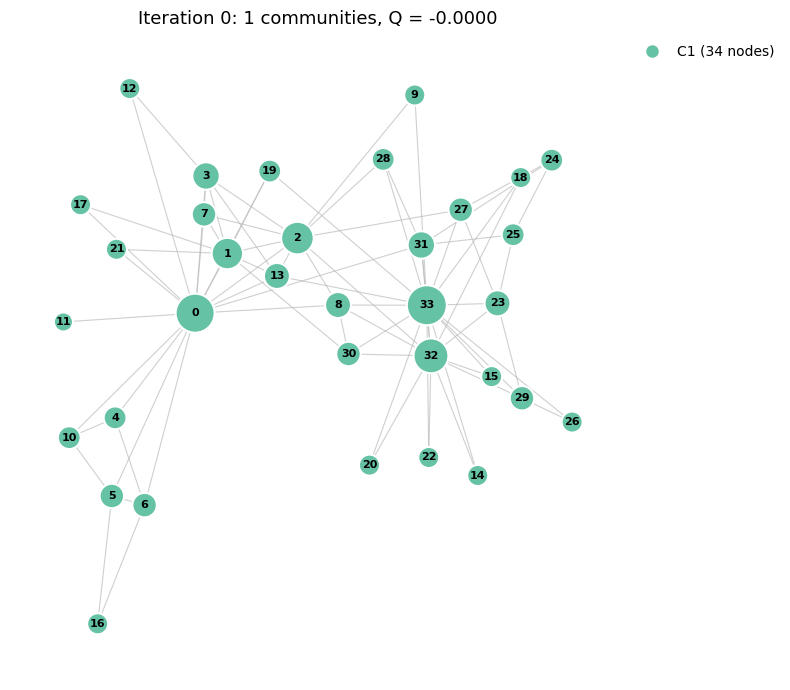

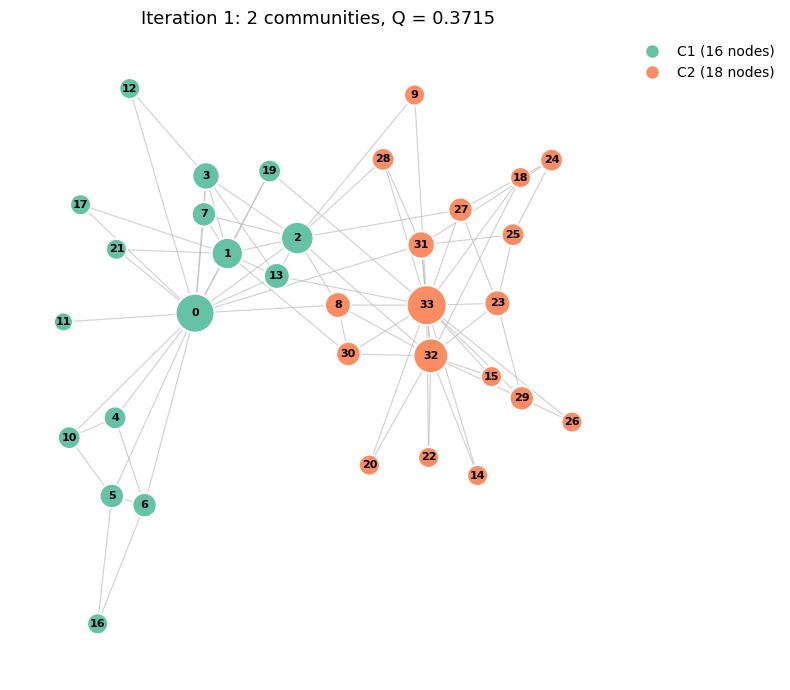

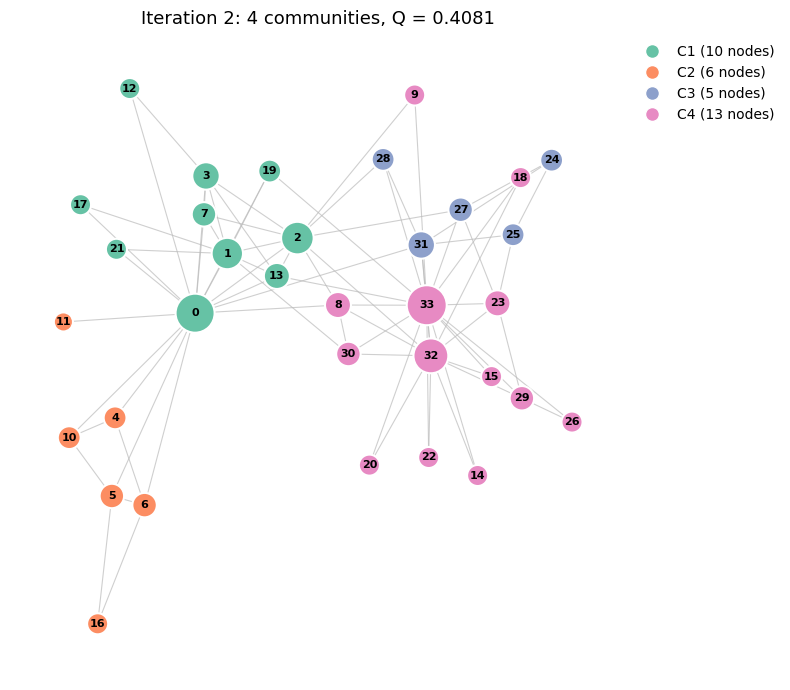

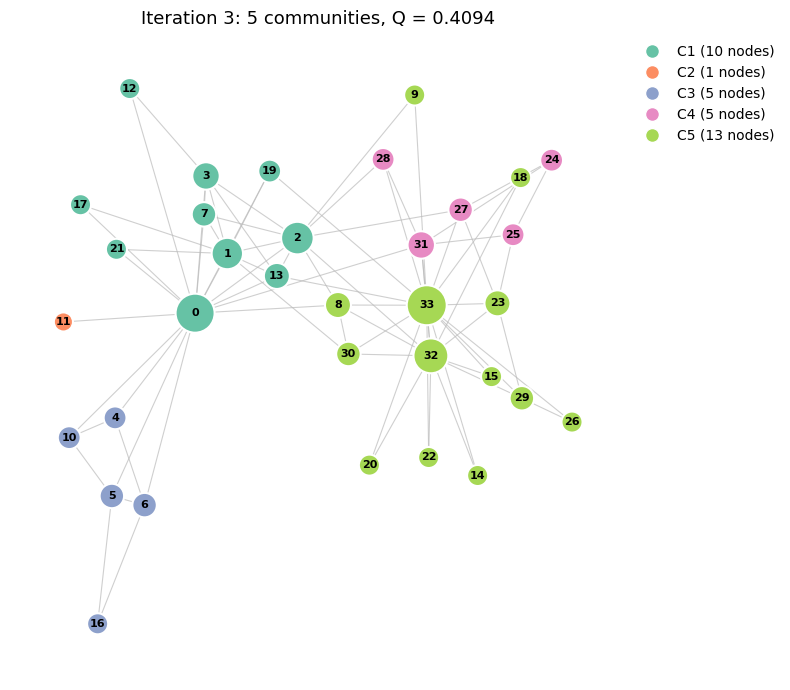

In [9]:
import matplotlib.cm as cm
from matplotlib.lines import Line2D

def draw_partition(partition, it):
    comm_of = {v: ci for ci, c in enumerate(partition) for v in c}
    palette = cm.Set2.colors + cm.Dark2.colors
    colors = [palette[comm_of[v] % len(palette)] for v in G.nodes()]
    sizes = [150 + 40 * G.degree(v) for v in G.nodes()]

    fig, ax = plt.subplots(figsize=(8, 7))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#bbbbbb', width=0.8, alpha=0.7)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=sizes,
                           edgecolors='white', linewidths=1.5)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight='bold')

    handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[i % len(palette)],
                      markersize=10, label=f"C{i+1} ({len(c)} nodes)")
               for i, c in enumerate(partition)]
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1, 1), frameon=False)

    Qi = modularity(partition, B, m)
    ax.set_title(f"Iteration {it}: {len(partition)} communities, Q = {Qi:.4f}", fontsize=13)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

for it, p in enumerate(history):
    draw_partition(p, it)

In [10]:
def within_graph(partition):
    comm_of = {v: ci for ci, c in enumerate(partition) for v in c}
    H = nx.Graph()
    H.add_nodes_from(G.nodes())
    H.add_edges_from((u, v) for u, v in G.edges() if comm_of[u] == comm_of[v])
    return H

metrics = {'degree': {}, 'betweenness': {}, 'closeness': {}, 'clustering': {}}

for it, p in enumerate(history):
    H = within_graph(p)
    metrics['degree'][it]      = nx.degree_centrality(H)
    metrics['betweenness'][it] = nx.betweenness_centrality(H)
    metrics['closeness'][it]   = nx.closeness_centrality(H)
    metrics['clustering'][it]  = nx.clustering(H)

In [11]:
for name in metrics:
    print(name)
    for it in metrics[name]:
        top = sorted(metrics[name][it].items(), key=lambda x: -x[1])[:4]
        print("  iter", it, [(v, round(val, 3)) for v, val in top])

degree
  iter 0 [(33, 0.515), (0, 0.485), (32, 0.364), (2, 0.303)]
  iter 1 [(33, 0.455), (0, 0.424), (32, 0.333), (1, 0.242)]
  iter 2 [(33, 0.364), (32, 0.303), (0, 0.273), (1, 0.242)]
  iter 3 [(33, 0.364), (32, 0.303), (0, 0.273), (1, 0.242)]
betweenness
  iter 0 [(0, 0.438), (33, 0.304), (32, 0.145), (2, 0.144)]
  iter 1 [(33, 0.147), (0, 0.137), (32, 0.052), (31, 0.029)]
  iter 2 [(33, 0.068), (32, 0.032), (0, 0.024), (1, 0.015)]
  iter 3 [(33, 0.068), (32, 0.032), (0, 0.024), (1, 0.015)]
closeness
  iter 0 [(0, 0.569), (2, 0.559), (33, 0.55), (31, 0.541)]
  iter 1 [(33, 0.461), (0, 0.426), (32, 0.381), (23, 0.302)]
  iter 2 [(33, 0.364), (32, 0.312), (0, 0.273), (1, 0.245)]
  iter 3 [(33, 0.364), (32, 0.312), (0, 0.273), (1, 0.245)]
clustering
  iter 0 [(7, 1.0), (12, 1.0), (14, 1.0), (15, 1.0)]
  iter 1 [(7, 1.0), (8, 1.0), (12, 1.0), (13, 1.0)]
  iter 2 [(7, 1.0), (8, 1.0), (12, 1.0), (13, 1.0)]
  iter 3 [(7, 1.0), (8, 1.0), (12, 1.0), (13, 1.0)]


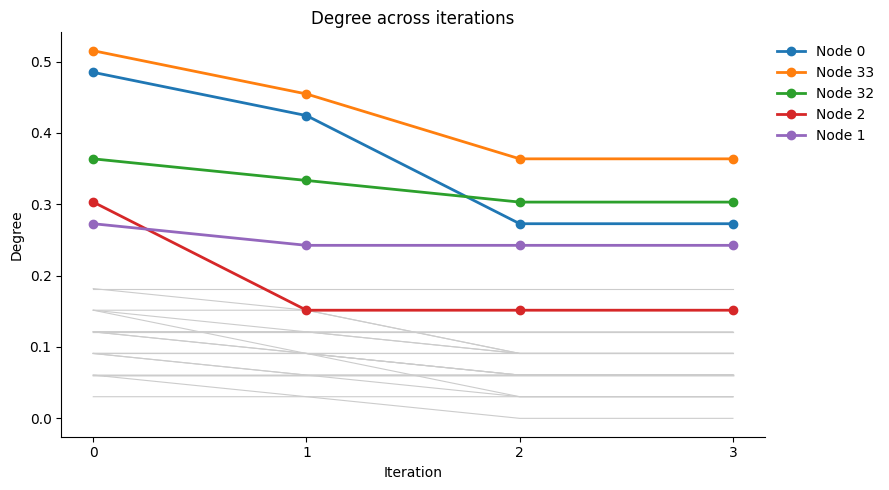

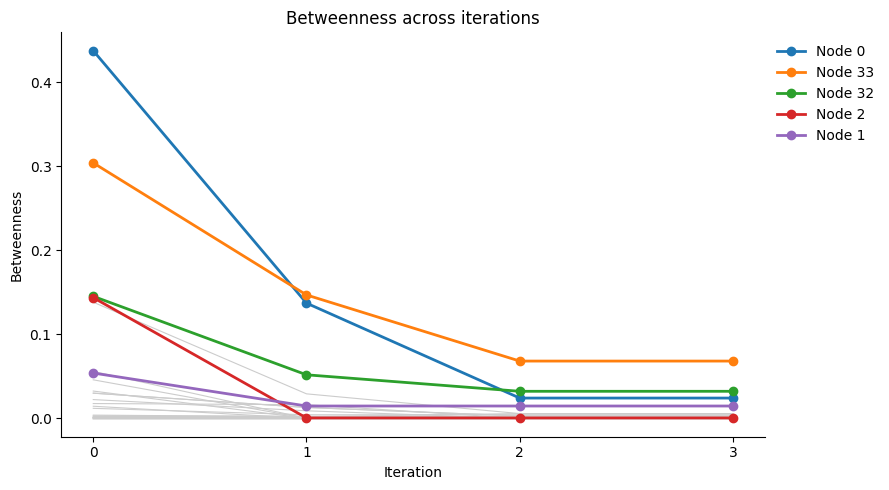

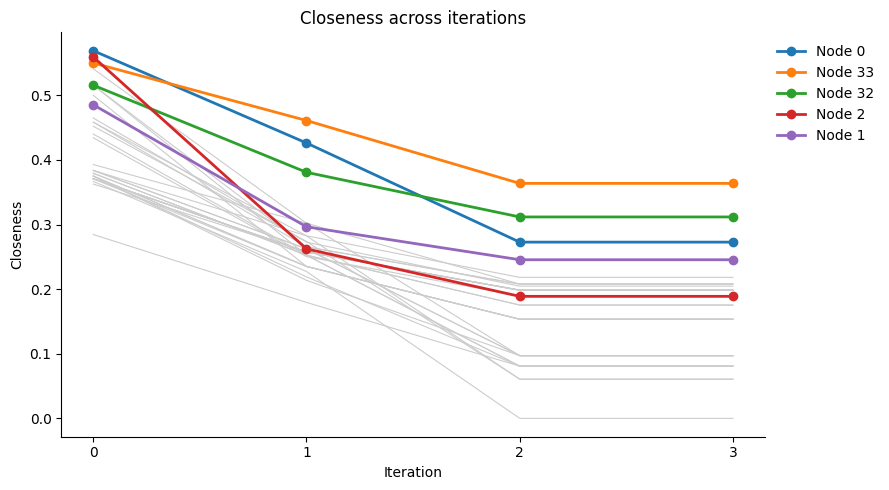

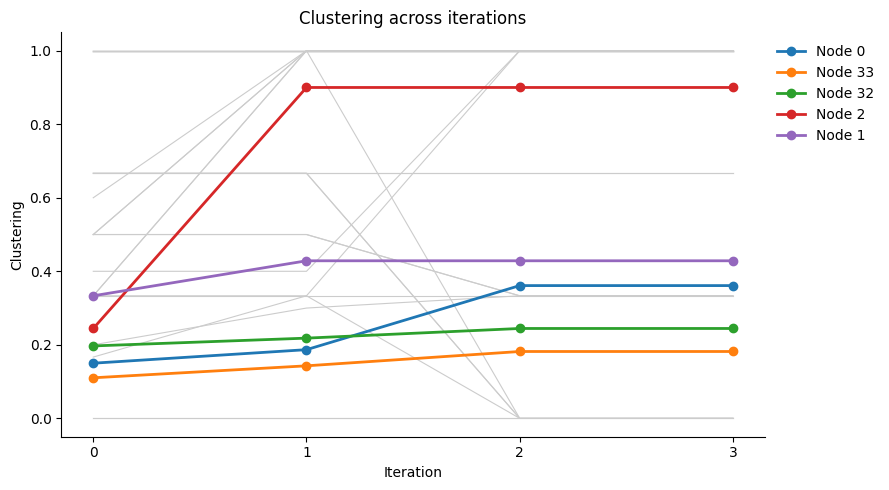

In [12]:
iters = list(range(len(history)))
highlight = [0, 33, 32, 2, 1]   # nodes to emphasise

def plot_metric(name):
    fig, ax = plt.subplots(figsize=(9, 5))
    for v in nodes:
        vals = [metrics[name][it][v] for it in iters]
        if v not in highlight:
            ax.plot(iters, vals, color='#cccccc', lw=0.8, zorder=1)
    for v in highlight:
        vals = [metrics[name][it][v] for it in iters]
        ax.plot(iters, vals, marker='o', lw=2, label=f"Node {v}", zorder=2)
    ax.set_xticks(iters)
    ax.set_xlabel("Iteration")
    ax.set_ylabel(name.capitalize())
    ax.set_title(f"{name.capitalize()} across iterations")
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()

for name in metrics:
    plot_metric(name)

## 8. Discussion

- Node 33 has the highest degree at every iteration
- Node 0 has the highest betweenness and closeness at iteration 0, then falls behind node 33 as its cross-community edges are removed
- Node 2 loses about half its edges at the first split; betweenness drops to $0$ and clustering rises
- Betweenness and closeness fall for almost all nodes, since paths between communities are cut
- Clustering mostly rises or stays flat, since remaining edges lie inside tight groups
- Iteration 3 only separates node 11 (single edge to node 0); no metric changes
- Limitation: node 11 ends up alone because $B^{(C)}$ is the plain sub-block, as in the handout